<div align="center">

# TUGAS RECIPES
## KECERDASAN ARTIFISIAL UNTUK GEOFISIKA

### IMPLEMENTASI DATA CURAH HUJAN DAN KEJADIAN LONGSOR
### KABUPATEN TANA TORAJA, 2020–2025

**Platform:** Python, Jupyter Notebook, Visual Studio Code

#### HARDIS HERO PRATAMA
#### NIM : H061241068

</div>

---

## 1. Pendahuluan dan tujuan

Notebook ini menyesuaikan format tugas contoh dengan empat file data yang diberikan: tabel curah hujan bulanan, daftar kejadian longsor, dan daftar kejadian longsor yang memiliki koordinat estimasi.

Tujuan pengerjaan:
1. Melakukan pemeriksaan kualitas data sebelum analisis.
2. Merangkum variasi curah hujan dan jumlah catatan longsor per bulan.
3. Mengeksplorasi korelasi curah hujan terdahulu dengan jumlah catatan longsor menggunakan jeda waktu (*lag correlation*).
4. Memetakan koordinat kejadian dan merangkum catatan per kecamatan.
5. Menyimpan tabel dan grafik agar proses dapat diulang di VS Code.

## 1.1 Recipes yang dipilih

| Recipe | Penggunaan pada dataset |
|---|---|
| **R-QC-001 — Membuat Data Quality Summary** | Memeriksa tanggal, nilai kosong, koordinat, duplikasi potensial, dan nilai curah hujan |
| **R-QC-002 — Mendeteksi Temporal Gap** | Memeriksa kelengkapan rangkaian bulanan |
| **R-ANA-001 — Exploratory Seasonal Summary** | Meringkas pola curah hujan bulanan dan tahunan |
| **R-CAL-003 — Lag Correlation untuk Time Series** | Mengeksplorasi hubungan waktu antara curah hujan dan jumlah catatan longsor |
| **R-GEO-001 — Memetakan GeoJSON di Atas Basemap atau Raster** | Diadaptasi untuk memetakan titik koordinat dari Excel; sumber belum berupa GeoJSON |
| **R-VIS-001 — Membuat Time-Series Figure yang Informatif** | Menampilkan pola deret waktu dan grafik hasil |

**Batasan:** data ini adalah data kebencanaan/geospasial berbasis hujan dan kejadian longsor, bukan data pengukuran geofisika langsung seperti seismik, resistivitas, atau gravitasi. Notebook ini belum membangun model kerawanan longsor yang tervalidasi.

## 0. Cara menjalankan di VS Code

1. Ekstrak ZIP proyek ke satu folder.
2. Buka folder tersebut di VS Code (**File → Open Folder**).
3. Pasang ekstensi **Python** dan **Jupyter** bila belum ada.
4. Pilih kernel Python 3.10+ (atau environment Python yang sudah memiliki dependensi).
5. Jalankan sel dari atas ke bawah dengan **Run All**.

Notebook membuat folder `outputs/` untuk tabel CSV dan grafik. File sumber tidak diubah.

### Dependensi
Jalankan sel berikut satu kali pada environment yang dipilih. Jika VS Code menyatakan modul belum tersedia, aktifkan terminal dengan environment yang sama lalu jalankan `python -m pip install pandas numpy matplotlib openpyxl python-docx`.

In [8]:
%pip install pandas numpy matplotlib openpyxl python-docx

Note: you may need to restart the kernel to use updated packages.


## 1. Persiapan lingkungan dan lokasi file

**Recipe terkait:** R-PRJ-002 (struktur proyek ilmiah) dan R-IO-001.  
Semua file input diasumsikan berada satu folder dengan notebook. Folder `outputs` digunakan untuk hasil turunan yang bisa dilacak.

In [9]:
from pathlib import Path
import re
import json
import calendar
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from docx import Document
from openpyxl import load_workbook
from IPython.display import display, Markdown

BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

RAIN_DOCX = BASE_DIR / "CURAH HUJAN STAMET TORAJA 2020-2025.docx"
EVENT_DOCX = BASE_DIR / "DATA LONGSOR TANA TORAJA 2020 - 2025.docx"
EVENT_XLSX = BASE_DIR / "Data_Tanah_Longsor_Tana_Toraja.xlsx"
COORD_XLSX = BASE_DIR / "Data_Longsor_Toraja_Berkoordinat.xlsx"

for path in [RAIN_DOCX, EVENT_DOCX, EVENT_XLSX, COORD_XLSX]:
    print(f"{path.name}: {'OK' if path.exists() else 'TIDAK DITEMUKAN'}")

CURAH HUJAN STAMET TORAJA 2020-2025.docx: OK
DATA LONGSOR TANA TORAJA 2020 - 2025.docx: OK
Data_Tanah_Longsor_Tana_Toraja.xlsx: OK
Data_Longsor_Toraja_Berkoordinat.xlsx: OK


## 2. Audit awal file Excel kejadian longsor

**Recipe:** R-QC-001 — Membuat Data Quality Summary.

Workbook berisi judul dan beberapa baris pemisah sebelum header tabel. Kode ini mencari baris header yang memuat kolom `Jenis Bencana` dan `Tanggal`, lalu membaca data setelahnya. Data asli tidak ditimpa.

In [10]:
def read_event_excel(path):
    wb = load_workbook(path, data_only=True, read_only=True)
    ws = wb[wb.sheetnames[0]]
    rows = list(ws.iter_rows(values_only=True))
    header_idx = None
    for i, row in enumerate(rows):
        vals = [str(v).strip().lower() if v is not None else "" for v in row]
        if "jenis bencana" in vals and "tanggal" in vals:
            header_idx = i
            headers = [str(v).strip() if v is not None else f"kolom_{j+1}" for j, v in enumerate(row)]
            break
    if header_idx is None:
        raise ValueError(f"Header tabel tidak ditemukan di {path.name}")
    records = []
    for row in rows[header_idx + 1:]:
        if not any(v is not None and str(v).strip() for v in row):
            continue
        record = {headers[j]: row[j] if j < len(row) else None for j in range(len(headers))}
        jenis = str(record.get("Jenis Bencana") or "").strip().lower()
        # Beberapa bagian tahunan mengulang baris header; jangan dihitung sebagai kejadian.
        if not jenis or jenis == "jenis bencana":
            continue
        records.append(record)
    return pd.DataFrame(records)

events = read_event_excel(EVENT_XLSX)
events_coord = read_event_excel(COORD_XLSX)

print("Baris kejadian (tanpa koordinat):", len(events))
print("Baris kejadian (dengan koordinat):", len(events_coord))
display(events.head())
display(events_coord.head())

Baris kejadian (tanpa koordinat): 101
Baris kejadian (dengan koordinat): 101


,No,Jenis Bencana,Tanggal,Kab/Kota,Kecamatan,Kelurahan/Lembang
0,1,Tanah Longsor,26 Oktober 2025,Kab. Tana Toraja,Makale,Bombongan
1,2,Tanah Longsor,18 April 2025,Kab. Tana Toraja,Sangalla Selatan,Raru Sibunuan
2,3,Tanah Longsor,12 April 2025,Kab. Tana Toraja,Mengkendek,NaN
3,4,Tanah Longsor,15 April 2025,Kab. Tana Toraja,Gandangbatu Sillanan,Buntu Tabang
4,5,Tanah Longsor,16 April 2025,Kab. Tana Toraja,Saluputi,Ratte Talonge


,No,Jenis Bencana,Tanggal,Kab/Kota,Kecamatan,Kelurahan/Lembang,Latitude,Longitude
0,1,Tanah Longsor,26 Oktober 2025,Kab. Tana Toraja,Makale,Bombongan,-3.1042,119.8631
1,2,Tanah Longsor,18 April 2025,Kab. Tana Toraja,Sangalla Selatan,Raru Sibunuan,-3.1512,119.9214
2,3,Tanah Longsor,12 April 2025,Kab. Tana Toraja,Mengkendek,NaN,-3.1500,119.8800
3,4,Tanah Longsor,15 April 2025,Kab. Tana Toraja,Gandangbatu Sillanan,Buntu Tabang,-3.2081,119.8943
4,5,Tanah Longsor,16 April 2025,Kab. Tana Toraja,Saluputi,Ratte Talonge,-3.0915,119.7824


## 3. Membersihkan tanggal dan koordinat secara transparan

**Recipe:** R-QC-001. Pembersihan hanya menstandarkan format, bukan mengubah fakta sumber. Nilai yang tidak dapat dibaca tetap menjadi `NaT`/`NaN` dan dilaporkan.

In [11]:
BULAN_ID = {
    "januari": 1, "februari": 2, "maret": 3, "april": 4,
    "mei": 5, "juni": 6, "juli": 7, "agustus": 8,
    "september": 9, "oktober": 10, "november": 11, "desember": 12
}

def parse_indonesian_date(value):
    if pd.isna(value):
        return pd.NaT
    if isinstance(value, (pd.Timestamp, np.datetime64)):
        return pd.to_datetime(value, errors="coerce")
    s = str(value).strip().lower()
    s = re.sub(r"\s+", " ", s)
    m = re.match(r"^(\d{1,2})\s+([a-z]+)\s+(\d{4})$", s)
    if m and m.group(2) in BULAN_ID:
        return pd.Timestamp(int(m.group(3)), BULAN_ID[m.group(2)], int(m.group(1)))
    return pd.to_datetime(s, errors="coerce", dayfirst=True)

for df in [events, events_coord]:
    df["Tanggal_asli"] = df["Tanggal"]
    df["Tanggal_parsed"] = df["Tanggal"].apply(parse_indonesian_date)
    df["Bulan"] = df["Tanggal_parsed"].dt.month
    df["Tahun"] = df["Tanggal_parsed"].dt.year

coord_cols = {str(c).strip().lower(): c for c in events_coord.columns}
lat_col = next((v for k, v in coord_cols.items() if k == "latitude"), None)
lon_col = next((v for k, v in coord_cols.items() if k == "longitude"), None)
if lat_col is None or lon_col is None:
    raise ValueError("Kolom Latitude/Longitude tidak ditemukan; periksa header Excel.")

events_coord["Latitude"] = pd.to_numeric(events_coord[lat_col], errors="coerce")
events_coord["Longitude"] = pd.to_numeric(events_coord[lon_col], errors="coerce")
events_coord["Koordinat_valid"] = (
    events_coord["Latitude"].between(-90, 90) &
    events_coord["Longitude"].between(-180, 180)
)

quality_summary = pd.DataFrame([
    {"pemeriksaan": "Jumlah baris kejadian", "nilai": len(events_coord)},
    {"pemeriksaan": "Tanggal gagal dibaca", "nilai": int(events_coord["Tanggal_parsed"].isna().sum())},
    {"pemeriksaan": "Latitude kosong/tidak valid", "nilai": int((~events_coord["Latitude"].between(-90, 90)).sum())},
    {"pemeriksaan": "Longitude kosong/tidak valid", "nilai": int((~events_coord["Longitude"].between(-180, 180)).sum())},
    {"pemeriksaan": "Baris tanpa nama kecamatan", "nilai": int(events_coord["Kecamatan"].isna().sum())},
    {"pemeriksaan": "Baris tanpa kelurahan/lembang", "nilai": int(events_coord["Kelurahan/Lembang"].isna().sum())},
])
display(quality_summary)
quality_summary.to_csv(OUTPUT_DIR / "01_quality_summary.csv", index=False)
events_coord.to_csv(OUTPUT_DIR / "02_long sor_events_audit.csv".replace(" ", ""), index=False)

,pemeriksaan,nilai
0,Jumlah baris kejadian,101
1,Tanggal gagal dibaca,0
2,Latitude kosong/tidak valid,0
3,Longitude kosong/tidak valid,0
4,Baris tanpa nama kecamatan,0
5,Baris tanpa kelurahan/lembang,3


## 4. Ekstraksi dan audit tabel curah hujan dari DOCX

**Recipe:** R-IO-001 + R-QC-001.

### Mengapa audit ini penting?
Header tabel sumber memiliki tahun yang berulang (`2021` dan `2022` muncul lebih dari sekali), serta ada nilai yang formatnya bermasalah (`628,,9`). Karena itu notebook **tidak menganggap tabel bersih secara otomatis**. Semua kolom sumber dipertahankan dalam tabel mentah; untuk analisis sementara, digunakan kolom pertama yang muncul untuk tiap tahun dan keputusan tersebut ditandai sebagai **provisional**. Nilai yang gagal dikonversi menjadi angka akan menjadi nilai kosong dan dilaporkan.

In [12]:
doc = Document(RAIN_DOCX)
if not doc.tables:
    raise ValueError("Tidak ada tabel di dokumen curah hujan.")
rain_table = doc.tables[0]
raw_rows = [[cell.text.strip() for cell in row.cells] for row in rain_table.rows]

raw_header = raw_rows[1]
raw_months = [row[0].strip() for row in raw_rows[2:] if row and row[0].strip()]
raw_rain_rows = [row for row in raw_rows[2:] if row and row[0].strip()]

rain_raw = pd.DataFrame(raw_rain_rows, columns=raw_header)
display(rain_raw.head())
print("Header tahun sebagaimana tertulis pada sumber:", raw_header)

,Bulan,2020,2021,2022,2021,2022,2023,2024,2025
0,Januari,"258,9","404,5","206,0","404,5",206.0,139.6,429.0,274.4
1,Februari,"482,3","235,0","254,6","235,0",254.6,121.8,440.0,225.9
2,Maret,"424,1","502,8","273,3","502,8",273.3,414.8,279.1,241.2
3,April,"669,9","262,1","352,2","262,1",352.2,364.9,492.8,379.2
4,Mei,"370,4","248,0","281,1","248,0",281.1,213.3,245.4,262.7


Header tahun sebagaimana tertulis pada sumber: ['Bulan', '2020', '2021', '2022', '2021', '2022', '2023', '2024', '2025']


In [13]:
def parse_rain_value(value):
    if value is None:
        return np.nan
    s = str(value).strip().replace(" ", "")
    # Koma desimal Indonesia; koma ganda dianggap kesalahan dan tidak diperbaiki diam-diam.
    if ",," in s:
        return np.nan
    if "," in s and "." not in s:
        s = s.replace(",", ".")
    try:
        return float(s)
    except (TypeError, ValueError):
        return np.nan

# Buat nama kolom unik agar kolom tahun berulang tidak tertimpa.
unique_headers = []
seen = {}
for h in raw_header:
    h = h.strip() or "kolom_kosong"
    seen[h] = seen.get(h, 0) + 1
    unique_headers.append(h if seen[h] == 1 else f"{h}_duplikat{seen[h]}")

rain_raw.columns = unique_headers
year_columns = [c for c in rain_raw.columns if re.fullmatch(r"20\d{2}(?:_duplikat\d+)?", c)]
print("Kolom tahun unik untuk audit:", year_columns)

# Provisional policy: gunakan kolom pertama untuk tiap tahun dan simpan audit perbandingan duplikat.
primary_cols = {}
for c in year_columns:
    year = int(c.split("_")[0])
    if year not in primary_cols:
        primary_cols[year] = c

rain_long_rows = []
for _, row in rain_raw.iterrows():
    month_name = str(row[raw_header[0].strip()]).strip() if raw_header[0].strip() in row.index else str(row.iloc[0]).strip()
    for year, col in primary_cols.items():
        rain_long_rows.append({
            "Bulan_nama": month_name,
            "Tahun": year,
            "Curah_hujan_mm": parse_rain_value(row[col]),
            "Kolom_sumber": col,
            "Status_pemilihan": "kolom pertama per tahun; perlu verifikasi sumber"
        })

rain = pd.DataFrame(rain_long_rows)
rain["Bulan"] = rain["Bulan_nama"].str.lower().map(BULAN_ID)
rain["Tanggal_bulan"] = pd.to_datetime(
    dict(year=rain["Tahun"], month=rain["Bulan"], day=1), errors="coerce"
)
rain = rain.sort_values("Tanggal_bulan").reset_index(drop=True)

rain_bad = rain[rain["Curah_hujan_mm"].isna()]
print("Nilai curah hujan yang gagal dibaca:", len(rain_bad))
display(rain_bad)
display(rain.head(15))

Kolom tahun unik untuk audit: ['2020', '2021', '2022', '2021_duplikat2', '2022_duplikat2', '2023', '2024', '2025']
Nilai curah hujan yang gagal dibaca: 1


,Bulan_nama,Tahun,Curah_hujan_mm,Kolom_sumber,Status_pemilihan,Bulan,Tanggal_bulan
22,November,2021,NaN,2021,kolom pertama per tahun; perlu verifikasi sumber,11,2021-11-01


,Bulan_nama,Tahun,Curah_hujan_mm,Kolom_sumber,Status_pemilihan,Bulan,Tanggal_bulan
0,Januari,2020,258.9,2020,kolom pertama per tahun; perlu verifikasi sumber,1,2020-01-01
1,Februari,2020,482.3,2020,kolom pertama per tahun; perlu verifikasi sumber,2,2020-02-01
2,Maret,2020,424.1,2020,kolom pertama per tahun; perlu verifikasi sumber,3,2020-03-01
3,April,2020,669.9,2020,kolom pertama per tahun; perlu verifikasi sumber,4,2020-04-01
4,Mei,2020,370.4,2020,kolom pertama per tahun; perlu verifikasi sumber,5,2020-05-01
5,Juni,2020,219.7,2020,kolom pertama per tahun; perlu verifikasi sumber,6,2020-06-01
6,Juli,2020,161.5,2020,kolom pertama per tahun; perlu verifikasi sumber,7,2020-07-01
7,Agustus,2020,106.3,2020,kolom pertama per tahun; perlu verifikasi sumber,8,2020-08-01
8,September,2020,125.1,2020,kolom pertama per tahun; perlu verifikasi sumber,9,2020-09-01
9,Oktober,2020,456.9,2020,kolom pertama per tahun; perlu verifikasi sumber,10,2020-10-01


### 4.1 Perbandingan kolom tahun yang berulang

Sebelum memakai hasil untuk laporan resmi, tinjau perbedaan kolom dengan label tahun yang sama. Notebook menampilkan nilai asli dan tidak menggabungkan/mengganti nilai tanpa keputusan pengguna.

In [14]:
duplicate_year_report = []
for year in sorted(set(int(c.split("_")[0]) for c in year_columns)):
    cols = [c for c in year_columns if int(c.split("_")[0]) == year]
    if len(cols) > 1:
        for _, row in rain_raw.iterrows():
            vals = {c: row[c] for c in cols}
            numeric_vals = [parse_rain_value(v) for v in vals.values()]
            numeric_vals = [v for v in numeric_vals if pd.notna(v)]
            duplicate_year_report.append({
                "Tahun_label": year,
                "Bulan": row.iloc[0],
                **vals,
                "Nilai_berbeda": len(set(numeric_vals)) > 1
            })
duplicate_year_report = pd.DataFrame(duplicate_year_report)
display(duplicate_year_report[duplicate_year_report["Nilai_berbeda"]].head(30))
duplicate_year_report.to_csv(OUTPUT_DIR / "03_audit_kolom_tahun_berulang.csv", index=False)

,Tahun_label,Bulan,2021,2021_duplikat2,Nilai_berbeda,2022,2022_duplikat2
19,2022,Agustus,NaN,NaN,True,248.4,248.2
22,2022,November,NaN,NaN,True,343.1,343.5
23,2022,Desember,NaN,NaN,True,352.4,352.6


## 5. Pemeriksaan kelengkapan deret bulanan

**Recipe:** R-QC-002 — Mendeteksi Temporal Gap.

Deret ideal memiliki satu nilai untuk setiap bulan pada rentang 2020–2025. Pemeriksaan ini menunjukkan bulan yang hilang atau nilai yang tidak terbaca; notebook tidak mengisi nilai yang hilang dengan interpolasi.

In [15]:
expected_months = pd.date_range("2020-01-01", "2025-12-01", freq="MS")
rain_indexed = rain.set_index("Tanggal_bulan")["Curah_hujan_mm"].reindex(expected_months)
temporal_gaps = pd.DataFrame({
    "Tanggal_bulan": expected_months,
    "Curah_hujan_mm": rain_indexed.values
})
temporal_gaps["Nilai_tidak_tersedia"] = temporal_gaps["Curah_hujan_mm"].isna()
print("Jumlah bulan pada rentang 2020–2025:", len(expected_months))
print("Bulan dengan nilai tidak tersedia:", int(temporal_gaps["Nilai_tidak_tersedia"].sum()))
display(temporal_gaps[temporal_gaps["Nilai_tidak_tersedia"]])
temporal_gaps.to_csv(OUTPUT_DIR / "04_temporal_gap_curah_hujan.csv", index=False)

Jumlah bulan pada rentang 2020–2025: 72
Bulan dengan nilai tidak tersedia: 1


,Tanggal_bulan,Curah_hujan_mm,Nilai_tidak_tersedia
22,2021-11-01,NaN,True


## 6. Ringkasan musiman dan tahunan

**Recipe:** R-ANA-001 — Exploratory Seasonal Summary.

Dalam notebook ini, musim hanya dibentuk sebagai kelompok bulan meteorologis sederhana untuk eksplorasi (DJF, MAM, JJA, SON). Ini bukan klasifikasi musim lokal yang telah divalidasi untuk Tana Toraja. Hasil ringkasan harus dibaca bersama catatan data hilang dan kolom tahun berulang.

In [16]:
rain_valid = rain.dropna(subset=["Tanggal_bulan", "Curah_hujan_mm"]).copy()
annual_rain = rain_valid.groupby("Tahun", as_index=False).agg(
    total_curah_hujan_mm=("Curah_hujan_mm", "sum"),
    rata_rata_bulanan_mm=("Curah_hujan_mm", "mean"),
    jumlah_bulan_valid=("Curah_hujan_mm", "count")
)
monthly_climatology = rain_valid.groupby("Bulan", as_index=False).agg(
    rata_rata_curah_hujan_mm=("Curah_hujan_mm", "mean"),
    median_curah_hujan_mm=("Curah_hujan_mm", "median"),
    jumlah_observasi=("Curah_hujan_mm", "count")
)
season_map = {12: "DJF", 1: "DJF", 2: "DJF",
              3: "MAM", 4: "MAM", 5: "MAM",
              6: "JJA", 7: "JJA", 8: "JJA",
              9: "SON", 10: "SON", 11: "SON"}
rain_valid["Musim_eksploratif"] = rain_valid["Bulan"].map(season_map)
season_summary = rain_valid.groupby(["Tahun", "Musim_eksploratif"], as_index=False).agg(
    total_curah_hujan_mm=("Curah_hujan_mm", "sum"),
    jumlah_bulan_valid=("Curah_hujan_mm", "count")
)

display(annual_rain)
display(monthly_climatology)
display(season_summary.head(12))
annual_rain.to_csv(OUTPUT_DIR / "05_ringkasan_curah_hujan_tahunan.csv", index=False)
monthly_climatology.to_csv(OUTPUT_DIR / "06_rata_rata_curah_hujan_bulanan.csv", index=False)
season_summary.to_csv(OUTPUT_DIR / "07_ringkasan_musiman_eksploratif.csv", index=False)

,Tahun,total_curah_hujan_mm,rata_rata_bulanan_mm,jumlah_bulan_valid
0,2020,3635.5,302.958333,12
1,2021,2561.1,232.827273,11
2,2022,2987.4,248.950000,12
3,2023,2007.9,167.325000,12
4,2024,3041.6,253.466667,12
5,2025,2673.3,222.775000,12


,Bulan,rata_rata_curah_hujan_mm,median_curah_hujan_mm,jumlah_observasi
0,1,285.400000,266.65,6
1,2,293.266667,244.80,6
2,3,355.883333,346.95,6
3,4,420.183333,372.05,6
4,5,270.150000,255.35,6
5,6,173.116667,164.30,6
6,7,145.250000,153.90,6
7,8,125.233333,105.65,6
8,9,99.350000,97.95,6
9,10,236.233333,216.55,6


,Tahun,Musim_eksploratif,total_curah_hujan_mm,jumlah_bulan_valid
0,2020,DJF,875.5,3
1,2020,JJA,487.5,3
2,2020,MAM,1464.4,3
3,2020,SON,808.1,3
4,2021,DJF,748.3,3
5,2021,JJA,382.3,3
6,2021,MAM,1012.9,3
7,2021,SON,417.6,2
8,2022,DJF,813.0,3
9,2022,JJA,590.3,3


## 7. Visualisasi deret waktu curah hujan

**Recipe:** R-VIS-001 — Membuat Time-Series Figure yang Informatif.

Grafik membantu melihat pola umum, lonjakan, dan kemungkinan data yang tidak konsisten. Grafik ini tidak digunakan untuk menyatakan tren signifikan secara statistik.

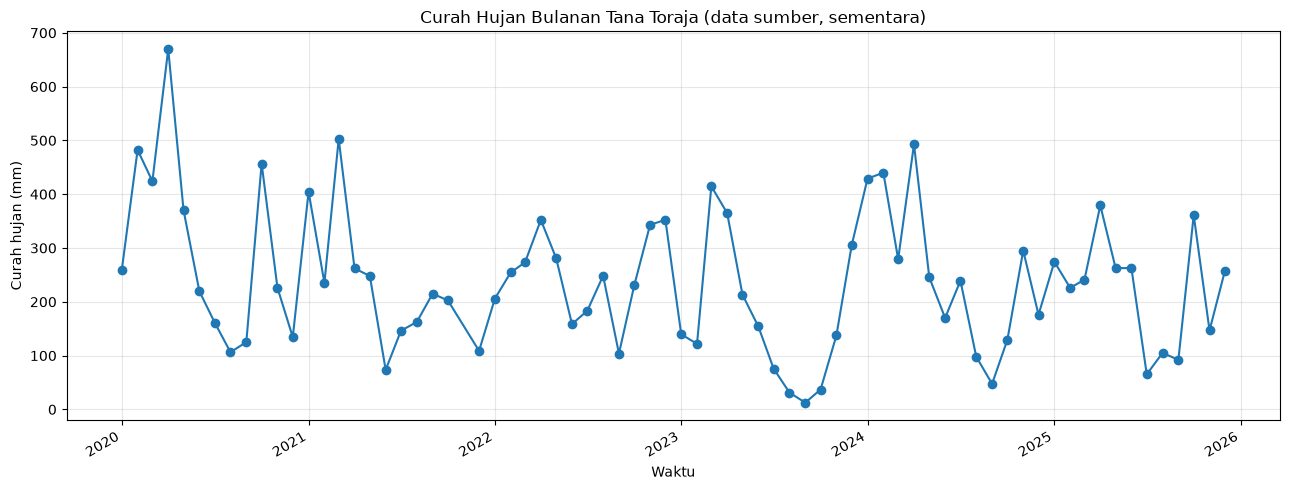

In [17]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(rain_valid["Tanggal_bulan"], rain_valid["Curah_hujan_mm"], marker="o", linewidth=1.5)
ax.set_title("Curah Hujan Bulanan Tana Toraja (data sumber, sementara)")
ax.set_xlabel("Waktu")
ax.set_ylabel("Curah hujan (mm)")
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "08_timeseries_curah_hujan.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Ringkasan kejadian longsor per bulan

Tanggal longsor diambil dari workbook kejadian. Data ini menunjukkan **jumlah catatan kejadian**, bukan intensitas atau luas longsor. Baris berulang bisa merupakan kejadian berbeda atau duplikasi sumber; notebook menandai tanggal dan lokasi yang sama agar ditinjau, bukan otomatis dihapus.

In [18]:
event_valid = events.copy()
event_valid = event_valid.dropna(subset=["Tanggal_parsed"])
event_valid["Tahun"] = event_valid["Tanggal_parsed"].dt.year
event_valid["Bulan"] = event_valid["Tanggal_parsed"].dt.month
event_valid["Tanggal_bulan"] = event_valid["Tanggal_parsed"].dt.to_period("M").dt.to_timestamp()

duplicate_key_cols = [c for c in ["Tanggal_parsed", "Kecamatan", "Kelurahan/Lembang"] if c in event_valid.columns]
event_valid["Potensi_duplikat"] = event_valid.duplicated(subset=duplicate_key_cols, keep=False)
potential_duplicates = event_valid[event_valid["Potensi_duplikat"]].sort_values(duplicate_key_cols)
print("Jumlah catatan kejadian dengan kombinasi tanggal/lokasi yang berulang:", len(potential_duplicates))
display(potential_duplicates[duplicate_key_cols].head(30))

event_monthly = event_valid.groupby("Tanggal_bulan", as_index=False).size().rename(columns={"size":"Jumlah_catatan_longsor"})
all_months = pd.DataFrame({"Tanggal_bulan": pd.date_range("2020-01-01", "2025-12-01", freq="MS")})
event_monthly = all_months.merge(event_monthly, on="Tanggal_bulan", how="left")
event_monthly["Jumlah_catatan_longsor"] = event_monthly["Jumlah_catatan_longsor"].fillna(0).astype(int)
display(event_monthly.head(12))
event_monthly.to_csv(OUTPUT_DIR / "09_jumlah_longsor_bulanan.csv", index=False)
potential_duplicates.to_csv(OUTPUT_DIR / "10_tinjau_potensi_duplikasi_longsor.csv", index=False)

Jumlah catatan kejadian dengan kombinasi tanggal/lokasi yang berulang: 2


,Tanggal_parsed,Kecamatan,Kelurahan/Lembang
50,2022-08-27,Rano,Rumandan
61,2022-08-27,Rano,Rumandan


,Tanggal_bulan,Jumlah_catatan_longsor
0,2020-01-01,2
1,2020-02-01,1
2,2020-03-01,1
3,2020-04-01,1
4,2020-05-01,0
5,2020-06-01,0
6,2020-07-01,0
7,2020-08-01,0
8,2020-09-01,0
9,2020-10-01,0


---

# RECIPE 1 — R-CAL-003: Lag Correlation untuk Time Series

## 9.1 Recipe overview

*Lag correlation* digunakan untuk mengeksplorasi apakah suatu deret waktu berkaitan dengan deret lain setelah jeda tertentu. Pada dataset ini, deret pemicu yang ditinjau adalah curah hujan bulanan \(R_t\), sedangkan respons yang ditinjau adalah jumlah catatan longsor bulanan \(L_t\).

\[
r(k)=\operatorname{corr}(R_{t-k}, L_t)
\]

- **Lag 0:** hujan dan catatan longsor pada bulan yang sama.
- **Lag 1:** hujan satu bulan sebelumnya dibandingkan dengan catatan longsor bulan berjalan.
- **Lag 2–3:** hujan dua atau tiga bulan sebelumnya.

## 9.2 When to use

Recipe ini sesuai karena data hujan sudah berbentuk bulanan dan tanggal longsor dapat diagregasi menjadi jumlah catatan per bulan. Kedua deret kemudian dapat diselaraskan dalam interval waktu yang sama.

## 9.3 Input dan output

| Parameter | Tipe/satuan | Keterangan |
|---|---|---|
| Curah hujan | numerik, mm/bulan | Deret observasi bulanan |
| Catatan longsor | integer, catatan/bulan | Jumlah baris kejadian per bulan |
| Lag | integer, bulan | Jeda yang diuji |
| Korelasi Pearson | −1 sampai +1 | Ukuran asosiasi linear |
| Jumlah pasangan | integer | Banyak pasangan valid untuk setiap lag |

## 9.4 Konsep dan algoritma

Untuk setiap nilai lag, deret curah hujan digeser ke masa lalu, kemudian dipasangkan dengan jumlah catatan longsor bulan target. Pasangan yang mengandung nilai hilang tidak digunakan. Notebook menampilkan jumlah pasangan agar pengguna mengetahui berapa banyak data yang menyokong setiap hasil.

**Batasan ilmiah:** korelasi bukan bukti kausalitas. Data bulanan tidak dapat menunjukkan jeda respons dalam jam atau hari; autokorelasi, musim, kondisi lereng, litologi, tutupan lahan, dan bias pelaporan dapat memengaruhi korelasi.

## 9. Eksplorasi hubungan curah hujan dan jumlah kejadian

**Recipe:** R-CAL-003 — Lag Correlation untuk Time Series.

Analisis menggabungkan curah hujan bulanan dengan jumlah catatan longsor pada bulan yang sama, kemudian menghitung korelasi Pearson pada lag 0–3 bulan. Untuk `lag = 1`, curah hujan satu bulan sebelumnya dibandingkan dengan jumlah longsor pada bulan berikutnya. Hasil bersifat eksploratif karena data hujan hanya bulanan, kemungkinan hanya mewakili satu stasiun, dan belum memperhitungkan faktor lereng/geologi/tutupan lahan.

,Lag_bulan,Jumlah_pasangan,Korelasi_Pearson
0,0,71,0.266787
1,1,70,0.012688
2,2,69,0.005576
3,3,68,-0.050128


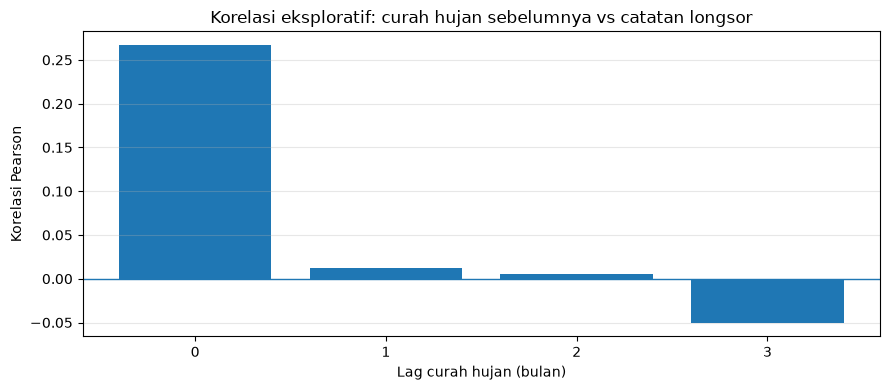

In [19]:
combined = rain[["Tanggal_bulan", "Curah_hujan_mm"]].merge(
    event_monthly, on="Tanggal_bulan", how="left"
).sort_values("Tanggal_bulan")
combined["Jumlah_catatan_longsor"] = combined["Jumlah_catatan_longsor"].fillna(0)

lag_rows = []
for lag in range(0, 4):
    # Curah hujan pada bulan t-lag dibandingkan dengan longsor bulan t
    rain_shifted = combined["Curah_hujan_mm"].shift(lag)
    pair = pd.DataFrame({
        "hujan": rain_shifted,
        "longsor": combined["Jumlah_catatan_longsor"]
    }).dropna()
    corr = pair["hujan"].corr(pair["longsor"]) if len(pair) >= 3 else np.nan
    lag_rows.append({"Lag_bulan": lag, "Jumlah_pasangan": len(pair), "Korelasi_Pearson": corr})
lag_results = pd.DataFrame(lag_rows)
display(lag_results)
combined.to_csv(OUTPUT_DIR / "11_gabungan_hujan_longsor_bulanan.csv", index=False)
lag_results.to_csv(OUTPUT_DIR / "12_korelasi_lag_eksploratif.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(lag_results["Lag_bulan"].astype(str), lag_results["Korelasi_Pearson"])
ax.axhline(0, linewidth=1)
ax.set_title("Korelasi eksploratif: curah hujan sebelumnya vs catatan longsor")
ax.set_xlabel("Lag curah hujan (bulan)")
ax.set_ylabel("Korelasi Pearson")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "13_korelasi_lag.png", dpi=180, bbox_inches="tight")
plt.show()

---

# RECIPE 2 — R-GEO-001: Pemetaan Spasial Titik Kejadian Longsor

## 10.1 Recipe overview

Recipe R-GEO-001 dalam buku membahas pemetaan data spasial di atas basemap atau raster. Karena dataset yang tersedia adalah Excel dengan kolom latitude dan longitude, implementasi disesuaikan menjadi pemetaan titik dasar dan ringkasan atribut. File batas administrasi, DEM, dan GeoJSON belum disediakan.

## 10.2 When to use

Recipe ini sesuai saat setiap kejadian memiliki koordinat yang dapat diperiksa dan dipetakan. Peta membantu melihat sebaran catatan yang tersedia, tetapi tidak otomatis menggambarkan probabilitas longsor atau tingkat kerawanan.

## 10.3 Input dan output

| Parameter | Tipe | Keterangan |
|---|---|---|
| Latitude | numerik, derajat desimal | Koordinat lintang |
| Longitude | numerik, derajat desimal | Koordinat bujur |
| Tanggal dan tahun | tanggal/integer | Untuk melihat perbedaan antarwaktu |
| Kecamatan | teks | Untuk agregasi jumlah catatan |
| Peta titik | grafik PNG | Sebaran koordinat dengan warna berdasarkan tahun |
| Ringkasan kecamatan | CSV | Jumlah catatan dan jumlah titik berkoordinat |

## 10.4 Konsep dan algoritma

Longitude diplot pada sumbu X dan latitude pada sumbu Y. Titik diberi warna berdasarkan tahun kejadian. Koordinat diperlakukan sebagai koordinat geografis derajat desimal (asumsi EPSG:4326), tetapi asumsi CRS perlu dikonfirmasi dari metadata sumber.

Koordinat pada nama file disebut sebagai estimasi spasial. Oleh karena itu, titik tidak boleh dianggap sebagai lokasi survei presisi tanpa verifikasi tambahan.

## 10. Pemetaan titik kejadian longsor berkoordinat

**Recipes:** R-IO-002 dan R-GEO-001.

Koordinat dalam file Excel diberi nama `Latitude` dan `Longitude`; peta dibuat pada CRS geografis **EPSG:4326**. Plot ini adalah pemeriksaan sebaran titik, bukan peta kerawanan. Belum ada batas administrasi atau DEM yang dioverlay. Titik koordinat estimasi harus diverifikasi terhadap sumbernya.

Titik yang dapat diplot: 101 dari 101


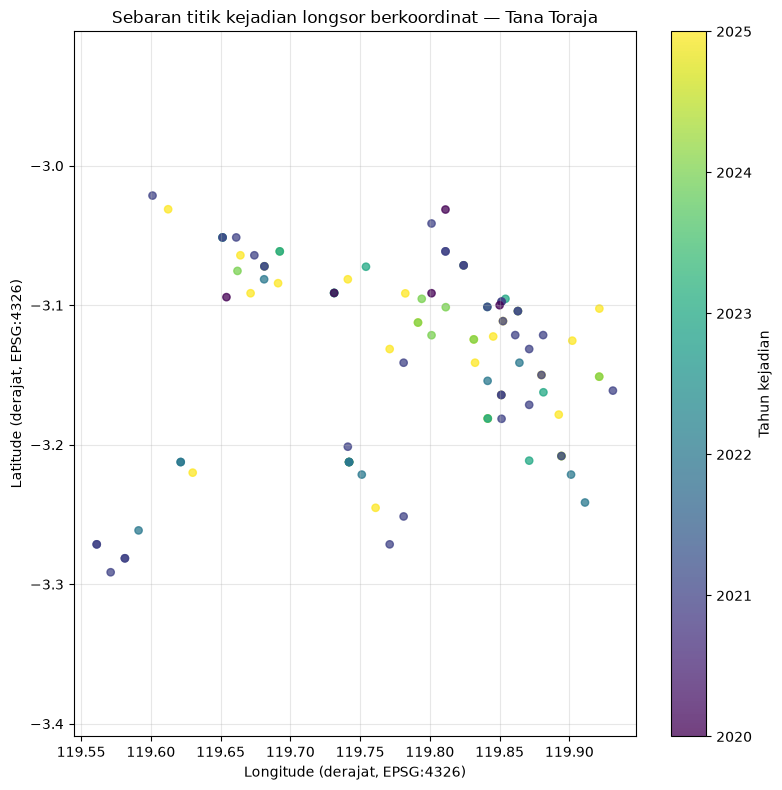

In [20]:
map_events = events_coord[events_coord["Koordinat_valid"] & events_coord["Tanggal_parsed"].notna()].copy()
print("Titik yang dapat diplot:", len(map_events), "dari", len(events_coord))

fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(map_events["Longitude"], map_events["Latitude"],
                c=map_events["Tanggal_parsed"].dt.year, s=28, alpha=0.75)
ax.set_title("Sebaran titik kejadian longsor berkoordinat — Tana Toraja")
ax.set_xlabel("Longitude (derajat, EPSG:4326)")
ax.set_ylabel("Latitude (derajat, EPSG:4326)")
ax.grid(True, alpha=0.3)
cb = fig.colorbar(sc, ax=ax)
cb.set_label("Tahun kejadian")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "14_peta_titik_longsor.png", dpi=180, bbox_inches="tight")
plt.show()

map_events.to_csv(OUTPUT_DIR / "15_titik_longsor_valid.csv", index=False)

## 11. Ringkasan hasil otomatis dan keterbatasan

Notebook merangkum ukuran data dan flag QA/QC untuk membantu penyusunan laporan. Angka yang keluar merupakan hasil pembacaan file yang ada pada folder proyek.

In [21]:
summary = {
    "jumlah_catatan_longsor_excel": int(len(events)),
    "jumlah_catatan_longsor_dengan_koordinat": int(len(events_coord)),
    "tanggal_longsor_gagal_dibaca": int(events_coord["Tanggal_parsed"].isna().sum()),
    "titik_koordinat_valid": int(events_coord["Koordinat_valid"].sum()),
    "jumlah_bulan_curah_hujan_dalam_tabel": int(len(rain)),
    "nilai_curah_hujan_gagal_dibaca": int(rain["Curah_hujan_mm"].isna().sum()),
    "rentang_tahun_curah_hujan": [int(rain["Tahun"].min()), int(rain["Tahun"].max())],
    "rentang_tahun_longsor": [
        int(events_coord["Tahun"].dropna().min()),
        int(events_coord["Tahun"].dropna().max())
    ]
}
print(json.dumps(summary, indent=2, ensure_ascii=False))
(OUTPUT_DIR / "16_summary_run.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")

{
  "jumlah_catatan_longsor_excel": 101,
  "jumlah_catatan_longsor_dengan_koordinat": 101,
  "tanggal_longsor_gagal_dibaca": 0,
  "titik_koordinat_valid": 101,
  "jumlah_bulan_curah_hujan_dalam_tabel": 72,
  "nilai_curah_hujan_gagal_dibaca": 1,
  "rentang_tahun_curah_hujan": [
    2020,
    2025
  ],
  "rentang_tahun_longsor": [
    2020,
    2025
  ]
}


355

## 12. Interpretasi ilmiah dan pekerjaan lanjutan

### Yang dapat dijawab oleh notebook ini
- Apakah ada nilai kosong, format salah, atau label tahun yang berulang?
- Bagaimana pola bulanan/tahunan curah hujan pada tabel yang tersedia?
- Berapa banyak catatan longsor per bulan/tahun?
- Di mana titik kejadian yang memiliki koordinat?
- Apakah terdapat pola korelasi eksploratif pada jeda waktu bulanan tertentu?

### Yang belum dapat disimpulkan
- **Belum dapat menghasilkan kelas kerawanan longsor yang tervalidasi.**
- Tidak bisa membuktikan bahwa hujan tertentu menyebabkan longsor tertentu.
- Belum bisa menghitung kontribusi elevasi atau kemiringan lereng karena DEM belum disertakan.
- Belum bisa memetakan kerawanan secara administratif tanpa batas kecamatan/desa yang sesuai.
- Koordinat estimasi tidak boleh disebut lokasi survei presisi tanpa metadata sumber.

### Data tambahan yang disarankan
1. DEMNAS/DEM resolusi sesuai untuk membuat elevasi dan slope.
2. Curah hujan harian dari stasiun atau produk gridded dengan metadata dan rentang waktu yang cocok.
3. Batas administrasi resmi (kabupaten, kecamatan, lembang/kelurahan).
4. Peta geologi/litologi dan tutupan lahan.
5. Metadata koordinat: sumber, metode estimasi, datum/CRS, dan tingkat ketelitian.

### Acuan recipe dari buku
- R-QC-001 — *Membuat Data Quality Summary*.
- R-QC-002 — *Mendeteksi Temporal Gap*.
- R-ANA-001 — *Exploratory Seasonal Summary*.
- R-IO-001 — *Membaca dan Merangkum Station CSV*.
- R-IO-002 — *Menormalisasi GeoJSON Tanpa Kehilangan Geometry*.
- R-GEO-001 — *Memetakan GeoJSON di Atas Basemap atau Raster*.
- R-VIS-001 — *Membuat Time-Series Figure yang Informatif*.
- R-CAL-003 — *Lag Correlation untuk Time Series*.

**Prinsip kerja:** data mentah dipertahankan; semua transformasi menghasilkan kolom/tabel baru; hasil harus ditinjau sebelum dipakai dalam laporan atau model.

---

# 13. Ringkasan, validasi, dan adaptasi

## 13.1 Perbandingan recipes

| Komponen | R-CAL-003 — Lag Correlation | R-GEO-001 — Pemetaan Titik |
|---|---|---|
| Pertanyaan | Apakah hujan terdahulu berasosiasi dengan catatan longsor? | Bagaimana distribusi koordinat kejadian yang tersedia? |
| Input | Hujan bulanan dan catatan longsor bulanan | Latitude, longitude, tanggal, kecamatan |
| Output | Tabel korelasi lag dan grafik temporal | Peta titik dan ringkasan kecamatan |
| Batasan | Tidak membuktikan sebab-akibat; data bulanan | Koordinat estimasi; tanpa basemap/batas administrasi belum menjadi peta kerawanan |

## 13.2 Validasi wajib

1. Periksa label tahun berulang pada tabel hujan dan cocokkan dengan sumber resmi.
2. Verifikasi nilai `628,,9` pada dokumen asli; notebook tidak mengoreksinya secara otomatis.
3. Tinjau potensi duplikasi catatan longsor sebelum memutuskan apakah baris perlu dihapus.
4. Konfirmasi CRS dan ketelitian koordinat.
5. Bandingkan catatan Excel dengan dokumen DOCX.
6. Hindari klaim kausal atau kelas kerawanan sampai data tambahan dan validasi tersedia.

## 13.3 Pengembangan selanjutnya

Untuk melanjutkan ke pemetaan kerawanan longsor, tambahkan DEM untuk elevasi dan slope, batas administrasi resmi, data geologi/litologi, tutupan lahan, dan data curah hujan harian atau spasial. Setelah itu, pilih metode pemodelan yang sesuai dan lakukan validasi menggunakan kejadian historis yang telah diverifikasi.

## 13.4 Referensi dan atribusi

1. Assagaf, A. (2026). *AI Cookbook untuk Earth Sciences: Prompt, Python, Scientific Modeling, dan Reproducible Workflows*. Edisi pertama. Buku acuan yang disertakan bersama tugas.
2. Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time Series Analysis: Forecasting and Control* (5th ed.). Wiley. https://doi.org/10.1002/9781118619193
3. Pearson, K. (1895). Notes on regression and inheritance in the case of two parents. *Proceedings of the Royal Society of London, 58*, 240–242.
4. Data curah hujan: `CURAH HUJAN STAMET TORAJA 2020-2025.docx` (file yang diberikan pengguna).
5. Data historis longsor: `Data_Tanah_Longsor_Tana_Toraja.xlsx` dan `DATA LONGSOR TANA TORAJA 2020 - 2025.docx` (file yang diberikan pengguna).
6. Data koordinat longsor: `Data_Longsor_Toraja_Berkoordinat.xlsx` (file yang diberikan pengguna).

---

*Notebook disusun untuk implementasi recipes pada mata kuliah Kecerdasan Artifisial untuk Geofisika. Semua hasil numerik perlu ditinjau setelah anomali data sumber diverifikasi.*